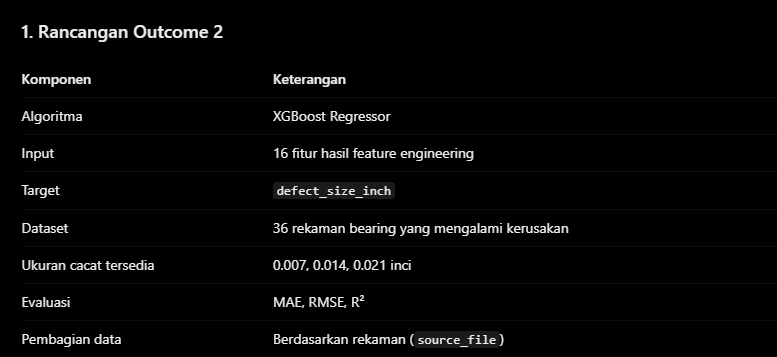

Outcome 2 bertujuan memperkirakan ukuran cacat bearing dalam satuan inci berdasarkan karakteristik sinyal getaran.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from xgboost import XGBRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Library berhasil diimport.")


Library berhasil diimport.


In [2]:
# Membaca dataset dan memilih data kerusakan
DATA_PATH = Path("outputs/bearing_features.csv")

df = pd.read_csv(DATA_PATH)

# Hanya menggunakan data bearing yang memiliki cacat
df_fault = df[
    df["defect_size_inch"].notna()
].copy()

print("Jumlah seluruh segmen:", len(df))
print("Jumlah segmen kerusakan:", len(df_fault))
print("Jumlah rekaman kerusakan:",
      df_fault["source_file"].nunique())

print("\nDistribusi ukuran cacat:")
print(df_fault["defect_size_inch"].value_counts().sort_index())

print("\nJumlah rekaman per ukuran cacat:")
print(
    df_fault.groupby("defect_size_inch")["source_file"]
    .nunique()
)

display(df_fault.head())


Jumlah seluruh segmen: 3993
Jumlah segmen kerusakan: 3641
Jumlah rekaman kerusakan: 36

Distribusi ukuran cacat:
defect_size_inch
0.007    1216
0.014    1212
0.021    1213
Name: count, dtype: int64

Jumlah rekaman per ukuran cacat:
defect_size_inch
0.007    12
0.014    12
0.021    12
Name: source_file, dtype: int64


,source_file,segment_id,start_sample,end_sample,condition,defect_size_inch,motor_load_hp,mean,std,rms,...,peak_amplitude,crest_factor,dominant_frequency,spectral_centroid,spectral_bandwidth,spectral_entropy,total_spectral_power,band_power_low,band_power_mid,band_power_high
352,105.mat,0,0,1199,Inner Race,0.007,0,0.000956,0.289800,0.289802,...,1.355075,4.675872,3597.65625,2772.476527,924.265706,6.546090,0.083186,0.004185,0.042934,0.036011
353,105.mat,1,1200,2399,Inner Race,0.007,0,0.000055,0.280380,0.280380,...,1.474303,5.258239,3585.93750,2694.696984,963.007090,6.791659,0.077066,0.005010,0.039990,0.032022
354,105.mat,2,2400,3599,Inner Race,0.007,0,-0.000649,0.291399,0.291400,...,1.191496,4.088872,2613.28125,2763.115273,876.139777,6.630757,0.089425,0.003862,0.049206,0.036272
355,105.mat,3,3600,4799,Inner Race,0.007,0,0.000697,0.287497,0.287498,...,1.289128,4.483954,3585.93750,2701.614027,897.545916,6.732841,0.081547,0.004402,0.047916,0.029176
356,105.mat,4,4800,5999,Inner Race,0.007,0,0.000368,0.286579,0.286579,...,1.553532,5.420950,3585.93750,2690.413644,912.402061,6.632021,0.083011,0.004231,0.048793,0.029937


In [3]:
# Menentukan fitur dan target regresi
feature_columns = [
    "mean", "std", "rms", "skewness",
    "kurtosis", "peak_to_peak",
    "peak_amplitude", "crest_factor",
    "dominant_frequency", "spectral_centroid",
    "spectral_bandwidth", "spectral_entropy",
    "total_spectral_power",
    "band_power_low", "band_power_mid",
    "band_power_high"
]

X = df_fault[feature_columns]
y = df_fault["defect_size_inch"]
groups = df_fault["source_file"]

assert np.isfinite(X.to_numpy()).all()
assert np.isfinite(y.to_numpy()).all()

print("Jumlah fitur:", X.shape[1])
print("Jumlah segmen:", X.shape[0])
print("Ukuran cacat:", sorted(y.unique()))


Jumlah fitur: 16
Jumlah segmen: 3641
Ukuran cacat: [np.float64(0.007), np.float64(0.014), np.float64(0.021)]


In [4]:
# Membagi training dan testing berdasarkan rekaman
from sklearn.model_selection import train_test_split

# Membuat metadata unik per rekaman
recording_info = (
    df_fault[
        ["source_file", "condition", "defect_size_inch"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Gabungkan jenis kerusakan dan ukuran cacat
recording_info["stratum"] = (
    recording_info["condition"].astype(str)
    + "_"
    + recording_info["defect_size_inch"].astype(str)
)

# Setiap kombinasi memiliki 4 rekaman (beban 0-3 HP)
train_files, test_files = train_test_split(
    recording_info["source_file"],
    test_size=0.25,
    random_state=42,
    stratify=recording_info["stratum"]
)

train_mask = df_fault["source_file"].isin(train_files)
test_mask = df_fault["source_file"].isin(test_files)

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

assert set(train_files).isdisjoint(set(test_files))

print("Jumlah file training:", len(train_files))
print("Jumlah file testing:", len(test_files))

print("\nDistribusi target training:")
print(y_train.value_counts().sort_index())

print("\nDistribusi target testing:")
print(y_test.value_counts().sort_index())


Jumlah file training: 27
Jumlah file testing: 9

Distribusi target training:
defect_size_inch
0.007    913
0.014    909
0.021    910
Name: count, dtype: int64

Distribusi target testing:
defect_size_inch
0.007    303
0.014    303
0.021    303
Name: count, dtype: int64


In [5]:
# Melatih XGBoost Regressor
model_xgb = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model_xgb.fit(X_train, y_train)

print("XGBoost Regressor berhasil dilatih!")


XGBoost Regressor berhasil dilatih!


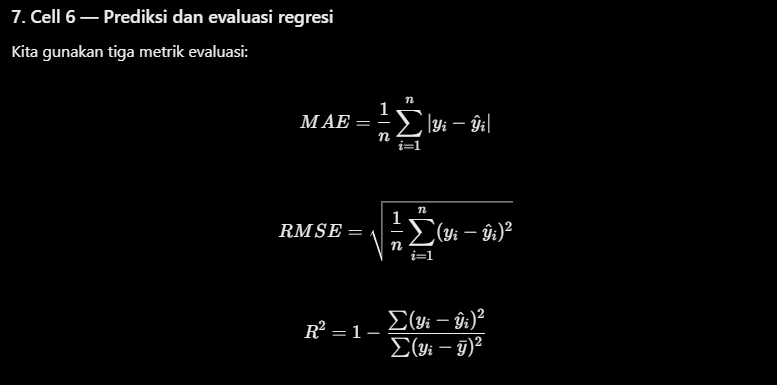

In [6]:
# Prediksi dan evaluasi regresi
y_pred = model_xgb.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Evaluasi XGBoost Regressor")
print("-" * 35)
print(f"MAE  : {mae:.6f} inch")
print(f"RMSE : {rmse:.6f} inch")
print(f"R²   : {r2:.4f}")

results_df = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred,
    "Absolute Error": np.abs(
        y_test.to_numpy() - y_pred
    )
})

display(results_df.head(10).round(6))


Evaluasi XGBoost Regressor
-----------------------------------
MAE  : 0.000648 inch
RMSE : 0.001195 inch
R²   : 0.9563


,Actual,Predicted,Absolute Error
0,0.007,0.007551,0.000551
1,0.007,0.007769,0.000769
2,0.007,0.007680,0.000680
3,0.007,0.007807,0.000807
4,0.007,0.006926,0.000074
5,0.007,0.007624,0.000624
6,0.007,0.006989,0.000011
7,0.007,0.007591,0.000591
8,0.007,0.008176,0.001176
9,0.007,0.006949,0.000051


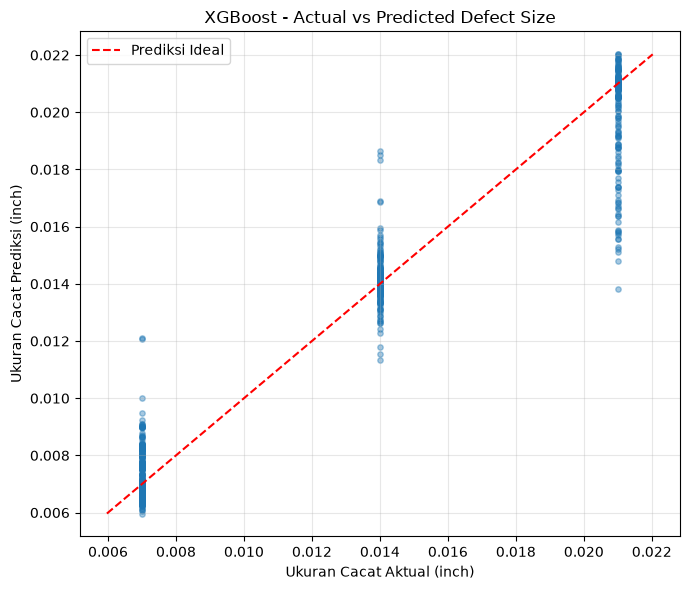

In [7]:
# Visualisasi aktual vs prediksi
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4,
    s=15
)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    color="red",
    label="Prediksi Ideal"
)

plt.title("XGBoost - Actual vs Predicted Defect Size")
plt.xlabel("Ukuran Cacat Aktual (inch)")
plt.ylabel("Ukuran Cacat Prediksi (inch)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
# Evaluasi kesalahan berdasarkan ukuran cacat
error_summary = (
    results_df
    .groupby("Actual")
    .agg(
        Samples=("Absolute Error", "count"),
        MAE=("Absolute Error", "mean"),
        Mean_Prediction=("Predicted", "mean")
    )
    .reset_index()
)

display(error_summary.round(6))


,Actual,Samples,MAE,Mean_Prediction
0,0.007,303,0.000670,0.007394
1,0.014,303,0.000439,0.014102
2,0.021,303,0.000836,0.020340


,Feature,Importance
13,band_power_low,0.164171
7,crest_factor,0.145397
1,std,0.129602
6,peak_amplitude,0.099165
2,rms,0.082432
12,total_spectral_power,0.077285
14,band_power_mid,0.061696
8,dominant_frequency,0.055480
15,band_power_high,0.052412
4,kurtosis,0.032373


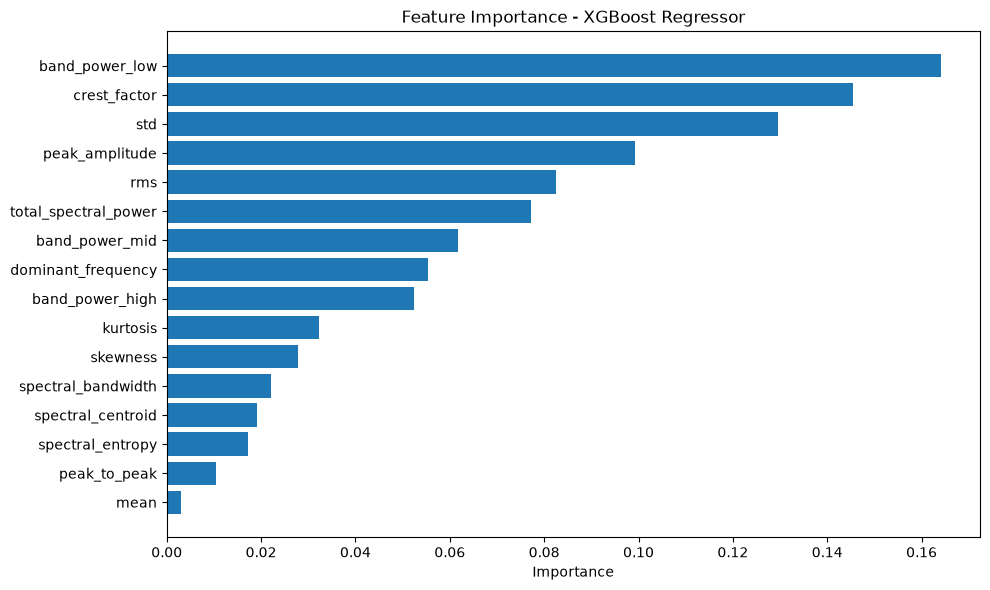

In [9]:
# Feature Importance
importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": model_xgb.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)

plt.title("Feature Importance - XGBoost Regressor")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [10]:
# Menyimpan model dan evaluasi
import joblib

MODEL_DIR = Path("outputs/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "model": model_xgb,
        "feature_columns": feature_columns,
        "target": "defect_size_inch"
    },
    MODEL_DIR / "xgboost_defect_size.joblib"
)

results_df.to_csv(
    "outputs/xgb_defect_predictions.csv",
    index=False
)

importance_df.to_csv(
    "outputs/xgb_feature_importance.csv",
    index=False
)

print("Model XGBoost dan hasil evaluasi berhasil disimpan.")


Model XGBoost dan hasil evaluasi berhasil disimpan.
